# Phase F2 — Supplementary canonical figures
### *Trustworthiness Under Compression* — the four expected visuals

Adds the canonical figures a top-tier trust paper is expected to have:
5. **Reliability diagrams** — M0 vs Prune80 vs Prune80+temperature (the calibration visual).
6. **AOPC deletion curves** — SHAP-ordered vs random feature deletion (the faithfulness visual).
7. **Accuracy-retention bar** — macro-F1 stays flat while trust collapses (the core tension).
8. **Deployability–trust Pareto** — size vs trust, annotated with accuracy (the practitioner's choice).

Self-contained: loads the seed-0 anchor + M1–M3 on CICIoT2023 test set. Saves 300-dpi PNG + PDF to `results/figures/`.

## 0. Setup + load models + test set

In [1]:
import os, gc, random, json
import numpy as np, pandas as pd, tensorflow as tf, joblib
import matplotlib.pyplot as plt
from matplotlib import rcParams
from scipy.optimize import minimize_scalar
rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'savefig.bbox':'tight'})

def seed_everything(s):
    os.environ['PYTHONHASHSEED']=str(s); random.seed(s); np.random.seed(s); tf.random.set_seed(s)
seed_everything(0)
ROOT='/content/drive/MyDrive/Trustworthiness_IoT'
if not os.path.isdir(f'{ROOT}/data'):
    from google.colab import drive; drive.mount('/content/drive')
CACHE=f'{ROOT}/data/cache'; MOD=f'{ROOT}/models'; RES=f'{ROOT}/results'; FIG=f'{RES}/figures'; os.makedirs(FIG,exist_ok=True)
CLASSES=['Benign','DDoS','DoS','Mirai','Recon','Spoofing','Web','BruteForce']
class_to_idx={c:i for i,c in enumerate(CLASSES)}; N_CLASSES=len(CLASSES)

df=pd.read_parquet(f'{CACHE}/ciciot_processed.parquet')
FEATURES=[c for c in df.columns if c!='y']
sp=np.load(f'{ROOT}/splits/split_primary.npz'); tr,te=sp['train'],sp['test']
scaler=joblib.load(f'{MOD}/scaler_primary.joblib')
Xa=df[FEATURES].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan).fillna(0.0).astype('float32')
y=df['y'].map(class_to_idx).astype('int64').values; del df; gc.collect()
Xtr=scaler.transform(Xa.iloc[tr]).astype('float32'); ytr=y[tr]
Xte=scaler.transform(Xa.iloc[te]).astype('float32'); yte=y[te]
del Xa; gc.collect()
N_FEATURES=Xte.shape[1]
anchor_path=f'{MOD}/M0_seed0.keras'
print('test',Xte.shape)

Mounted at /content/drive
test (7002987, 46)


In [2]:
# unified proba with MODEL CACHING (avoid reloading from Drive on every call)
_KERAS={}; _TFL={}
def _get_keras(path):
    if path not in _KERAS: _KERAS[path]=tf.keras.models.load_model(path)
    return _KERAS[path]
def _get_tfl(path):
    if path not in _TFL:
        it=tf.lite.Interpreter(model_path=path); it.allocate_tensors(); _TFL[path]=it
    return _TFL[path]

def proba(path,kind,X,batch=8192):
    if kind=='keras':
        return _get_keras(path).predict(X,batch_size=batch,verbose=0)
    it=_get_tfl(path)
    ii=it.get_input_details()[0]['index']; oo=it.get_output_details()[0]['index']
    dt=it.get_input_details()[0]['dtype']
    P=np.zeros((len(X),N_CLASSES),'float32')
    for i in range(len(X)):
        it.set_tensor(ii,X[i:i+1].astype(dt)); it.invoke(); P[i]=it.get_tensor(oo)[0]
    P=np.clip(P,0,None); s=P.sum(1,keepdims=True); s[s==0]=1; return P/s

VAR={'M0':(anchor_path,'keras'),'Prune50':(f'{MOD}/M2_prune50.keras','keras'),
     'Prune80':(f'{MOD}/M2_prune80.keras','keras'),'Distill':(f'{MOD}/M3_distilled.keras','keras'),
     'int8':(f'{MOD}/M1_int8.tflite','tflite'),'fp16':(f'{MOD}/M1_float16.tflite','tflite')}
PROB={n:proba(p,k,Xte) for n,(p,k) in VAR.items()}
print('probs computed for', list(PROB.keys()))

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


probs computed for ['M0', 'Prune50', 'Prune80', 'Distill', 'int8', 'fp16']


## Figure 5 — Reliability diagrams (calibration visual)

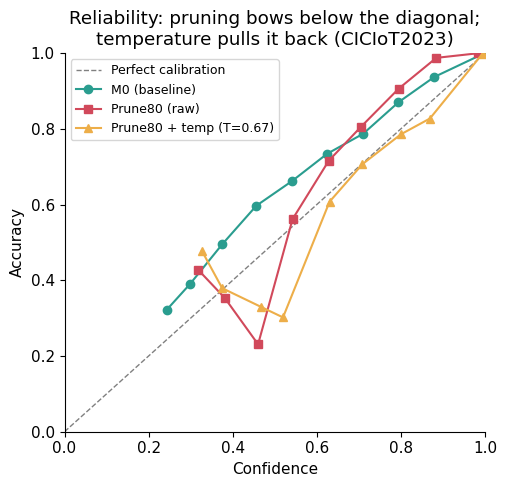

saved fig5


In [3]:
def reliability(P,yt,nbins=12):
    conf=P.max(1); pred=P.argmax(1); corr=(pred==yt).astype(float)
    edges=np.linspace(0,1,nbins+1); xs=[]; ys=[]
    for i in range(nbins):
        m=(conf>=edges[i])&(conf<edges[i+1])
        if m.sum()>20: xs.append(conf[m].mean()); ys.append(corr[m].mean())
    return np.array(xs),np.array(ys)

def temp(P,T):
    z=np.log(np.clip(P,1e-9,1))/T; z-=z.max(1,keepdims=True); e=np.exp(z); return e/e.sum(1,keepdims=True)
def fitT(P,yt):
    return float(minimize_scalar(lambda T:-np.mean(np.log(temp(P,T)[np.arange(len(yt)),yt]+1e-9)),bounds=(0.5,5),method='bounded').x)

fig,ax=plt.subplots(figsize=(5.2,5))
ax.plot([0,1],[0,1],'--',color='gray',lw=1,label='Perfect calibration')
x,yv=reliability(PROB['M0'],yte); ax.plot(x,yv,'o-',color='#2a9d8f',label='M0 (baseline)')
x,yv=reliability(PROB['Prune80'],yte); ax.plot(x,yv,'s-',color='#d1495b',label='Prune80 (raw)')
T=fitT(PROB['Prune80'],yte); x,yv=reliability(temp(PROB['Prune80'],T),yte)
ax.plot(x,yv,'^-',color='#edae49',label=f'Prune80 + temp (T={T:.2f})')
ax.set_xlabel('Confidence'); ax.set_ylabel('Accuracy'); ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.legend(fontsize=9,loc='upper left'); ax.set_title('Reliability: pruning bows below the diagonal;\ntemperature pulls it back (CICIoT2023)')
fig.tight_layout(); fig.savefig(f'{FIG}/fig5_reliability.png',dpi=300); fig.savefig(f'{FIG}/fig5_reliability.pdf'); plt.show()
print('saved fig5')

## Figure 6 — AOPC deletion curves (faithfulness visual)

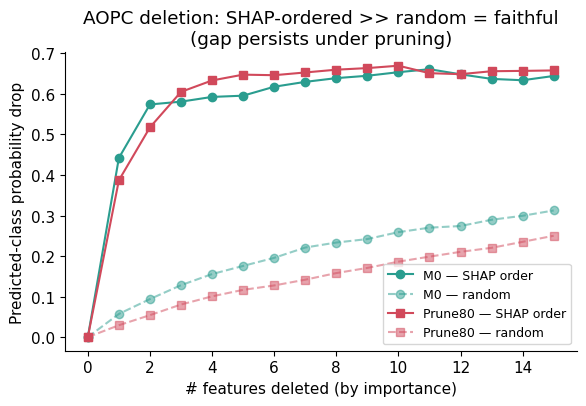

saved fig6


In [4]:
# Load cached SHAP true-class attributions (Phase C v2) + the eval subset they were computed on
SH=f'{ROOT}/results/shap_v2'
A_m0=np.load(f'{SH}/M0_s0_es0.npy'); A_p80=np.load(f'{SH}/M2_prune80_es0.npy')
# rebuild the SAME eval subset Phase C used (seed 0, 80/class)
rng=np.random.RandomState(0); sel=[]
for ci in range(N_CLASSES):
    pool=np.where(yte==ci)[0]; sel.append(rng.choice(pool,min(80,len(pool)),replace=False))
sel=np.concatenate(sel); Xev=Xte[sel]
mean_vec=Xtr.mean(0)

def deletion_curve(predict_path, predict_kind, A, X, ks=range(0,16)):
    P0=proba(predict_path,predict_kind,X); pred=P0.argmax(1); base=P0[np.arange(len(X)),pred]
    shap_drop=[]; rand_drop=[]
    for k in ks:
        if k==0: shap_drop.append(0.0); rand_drop.append(0.0); continue
        Xs=X.copy()
        for i in range(len(X)):
            tk=np.argsort(-np.abs(A[i]))[:k]; Xs[i,tk]=mean_vec[tk]
        ps=proba(predict_path,predict_kind,Xs)[np.arange(len(X)),pred]; shap_drop.append(np.mean(base-ps))
        rd=[]
        for d in range(3):
            r=np.random.RandomState(d); Xr=X.copy()
            for i in range(len(X)):
                rk=r.choice(N_FEATURES,k,replace=False); Xr[i,rk]=mean_vec[rk]
            rd.append(np.mean(base-proba(predict_path,predict_kind,Xr)[np.arange(len(X)),pred]))
        rand_drop.append(np.mean(rd))
    return list(ks),shap_drop,rand_drop

ks,m0_s,m0_r=deletion_curve(anchor_path,'keras',A_m0,Xev)
_,p8_s,p8_r=deletion_curve(f'{MOD}/M2_prune80.keras','keras',A_p80,Xev)
fig,ax=plt.subplots(figsize=(6,4.2))
ax.plot(ks,m0_s,'o-',color='#2a9d8f',label='M0 — SHAP order')
ax.plot(ks,m0_r,'o--',color='#2a9d8f',alpha=0.5,label='M0 — random')
ax.plot(ks,p8_s,'s-',color='#d1495b',label='Prune80 — SHAP order')
ax.plot(ks,p8_r,'s--',color='#d1495b',alpha=0.5,label='Prune80 — random')
ax.set_xlabel('# features deleted (by importance)'); ax.set_ylabel('Predicted-class probability drop')
ax.legend(fontsize=9); ax.set_title('AOPC deletion: SHAP-ordered >> random = faithful\n(gap persists under pruning)')
fig.tight_layout(); fig.savefig(f'{FIG}/fig6_aopc_curves.png',dpi=300); fig.savefig(f'{FIG}/fig6_aopc_curves.pdf'); plt.show()
print('saved fig6')

## Figure 7 — Accuracy retention (the core tension)

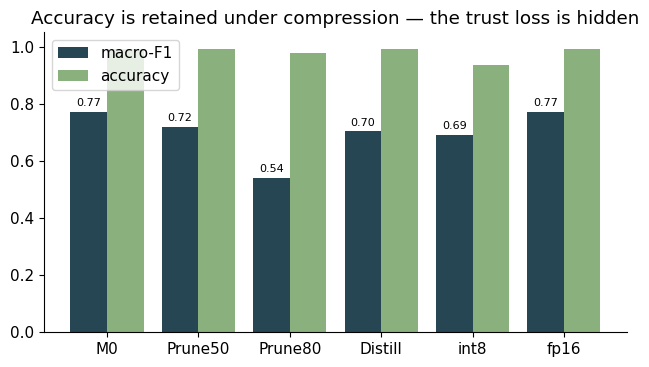

saved fig7


In [5]:
from sklearn.metrics import f1_score
order=['M0','Prune50','Prune80','Distill','int8','fp16']
f1=[f1_score(yte,PROB[n].argmax(1),average='macro') for n in order]
acc=[(PROB[n].argmax(1)==yte).mean() for n in order]
fig,ax=plt.subplots(figsize=(6.5,3.8))
x=np.arange(len(order))
ax.bar(x-0.2,f1,0.4,label='macro-F1',color='#264653')
ax.bar(x+0.2,acc,0.4,label='accuracy',color='#8ab17d')
ax.set_xticks(x); ax.set_xticklabels(order); ax.set_ylim(0,1.05); ax.legend()
ax.set_title('Accuracy is retained under compression — the trust loss is hidden')
for i,v in enumerate(f1): ax.text(i-0.2,v+0.02,f'{v:.2f}',ha='center',fontsize=8)
fig.tight_layout(); fig.savefig(f'{FIG}/fig7_accuracy_retention.png',dpi=300); fig.savefig(f'{FIG}/fig7_accuracy_retention.pdf'); plt.show()
print('saved fig7')

## Figure 8 — Deployability–trust Pareto (practitioner's choice)

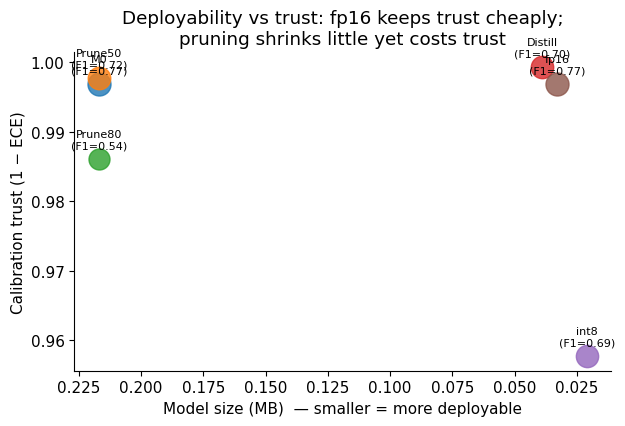

saved fig8


In [6]:
cal=pd.read_csv(f'{RES}/calibration_test.csv').set_index('model')
fag=pd.read_csv(f'{RES}/faithfulness_agreement_v2.csv').set_index('comparison')
name_map={'M0':'M0_anchor','Prune50':'M2_prune50','Prune80':'M2_prune80','Distill':'M3_distilled','int8':'M1_int8','fp16':'M1_float16'}
sizes={'M0':0.217,'Prune50':0.217,'Prune80':0.217,'Distill':0.039,'int8':0.021,'fp16':0.033}
fig,ax=plt.subplots(figsize=(6.4,4.4))
for n in order:
    key=name_map[n]
    ece=cal.loc[key,'ECE_raw'] if key in cal.index else np.nan
    trust=1-ece            # higher = better calibrated
    f1v=f1_score(yte,PROB[n].argmax(1),average='macro')
    ax.scatter(sizes[n],trust,s=120+f1v*200,alpha=0.8)
    ax.annotate(f'{n}\n(F1={f1v:.2f})',(sizes[n],trust),fontsize=8,ha='center',va='bottom',xytext=(0,6),textcoords='offset points')
ax.set_xlabel('Model size (MB)  — smaller = more deployable'); ax.set_ylabel('Calibration trust (1 − ECE)')
ax.set_title('Deployability vs trust: fp16 keeps trust cheaply;\npruning shrinks little yet costs trust')
ax.invert_xaxis()  # more deployable to the right
fig.tight_layout(); fig.savefig(f'{FIG}/fig8_pareto.png',dpi=300); fig.savefig(f'{FIG}/fig8_pareto.pdf'); plt.show()
print('saved fig8')

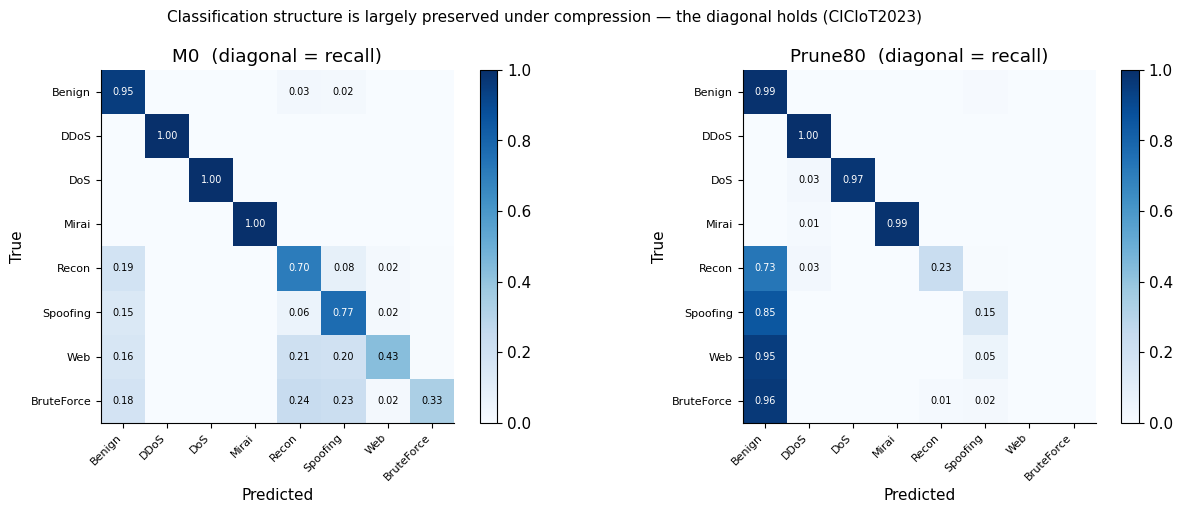

saved fig9


In [8]:
# Fig 9 (appendix) — confusion matrices: M0 vs Prune80 (row-normalised)
from sklearn.metrics import confusion_matrix
import numpy as np, matplotlib.pyplot as plt

fig,axes=plt.subplots(1,2,figsize=(13,5.2))
for ax,name in zip(axes,['M0','Prune80']):
    cm=confusion_matrix(yte, PROB[name].argmax(1), labels=range(len(CLASSES)))
    cmn=cm/cm.sum(1,keepdims=True).clip(min=1)          # row-normalise (recall per class)
    im=ax.imshow(cmn,cmap='Blues',vmin=0,vmax=1)
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES,fontsize=8)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{name}  (diagonal = recall)')
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            v=cmn[i,j]
            if v>0.01:
                ax.text(j,i,f'{v:.2f}',ha='center',va='center',fontsize=7,
                        color='white' if v>0.5 else 'black')
    fig.colorbar(im,ax=ax,fraction=0.046)
fig.suptitle('Classification structure is largely preserved under compression — the diagonal holds (CICIoT2023)',fontsize=11)
fig.tight_layout()
fig.savefig(f'{FIG}/fig9_confusion.png',dpi=300); fig.savefig(f'{FIG}/fig9_confusion.pdf')
plt.show(); print('saved fig9')

## Commit

In [7]:
print('figures now:', sorted(os.listdir(f'{ROOT}/results/figures')))
# !git -C "{ROOT}" add results/figures notebooks/
# !git -C "{ROOT}" commit -q -m "Phase F2: reliability, AOPC curves, accuracy retention, Pareto"
# !git -C "{ROOT}" push origin main

figures now: ['fig1_trust_gradient.pdf', 'fig1_trust_gradient.png', 'fig2_convergence.pdf', 'fig2_convergence.png', 'fig3_transfer.pdf', 'fig3_transfer.png', 'fig4_remedy.pdf', 'fig4_remedy.png', 'fig5_reliability.pdf', 'fig5_reliability.png', 'fig6_aopc_curves.pdf', 'fig6_aopc_curves.png', 'fig7_accuracy_retention.pdf', 'fig7_accuracy_retention.png', 'fig8_pareto.pdf', 'fig8_pareto.png']


## Read the output
- **Fig 5 reliability:** M0 hugs the diagonal; Prune80 bows below (overconfident); +temp pulls it back. The calibration visual.
- **Fig 6 AOPC:** SHAP-ordered curve far above random = explanations are faithful; the gap persists under pruning (behaviourally faithful even as attributions drift).
- **Fig 7 accuracy:** macro-F1 flat across variants = the hidden-trust-loss tension in one glance.
- **Fig 8 Pareto:** fp16 sits top-right (deployable + trusted); Prune80 bottom (shrinks little, loses trust) — the practitioner takeaway.